Dataset loaded successfully. Shape: (150, 5)


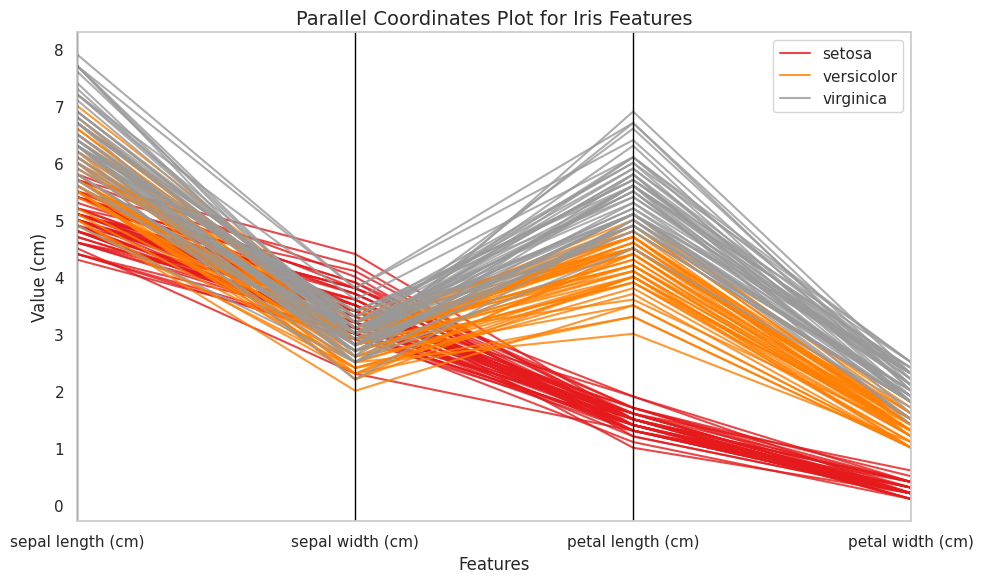

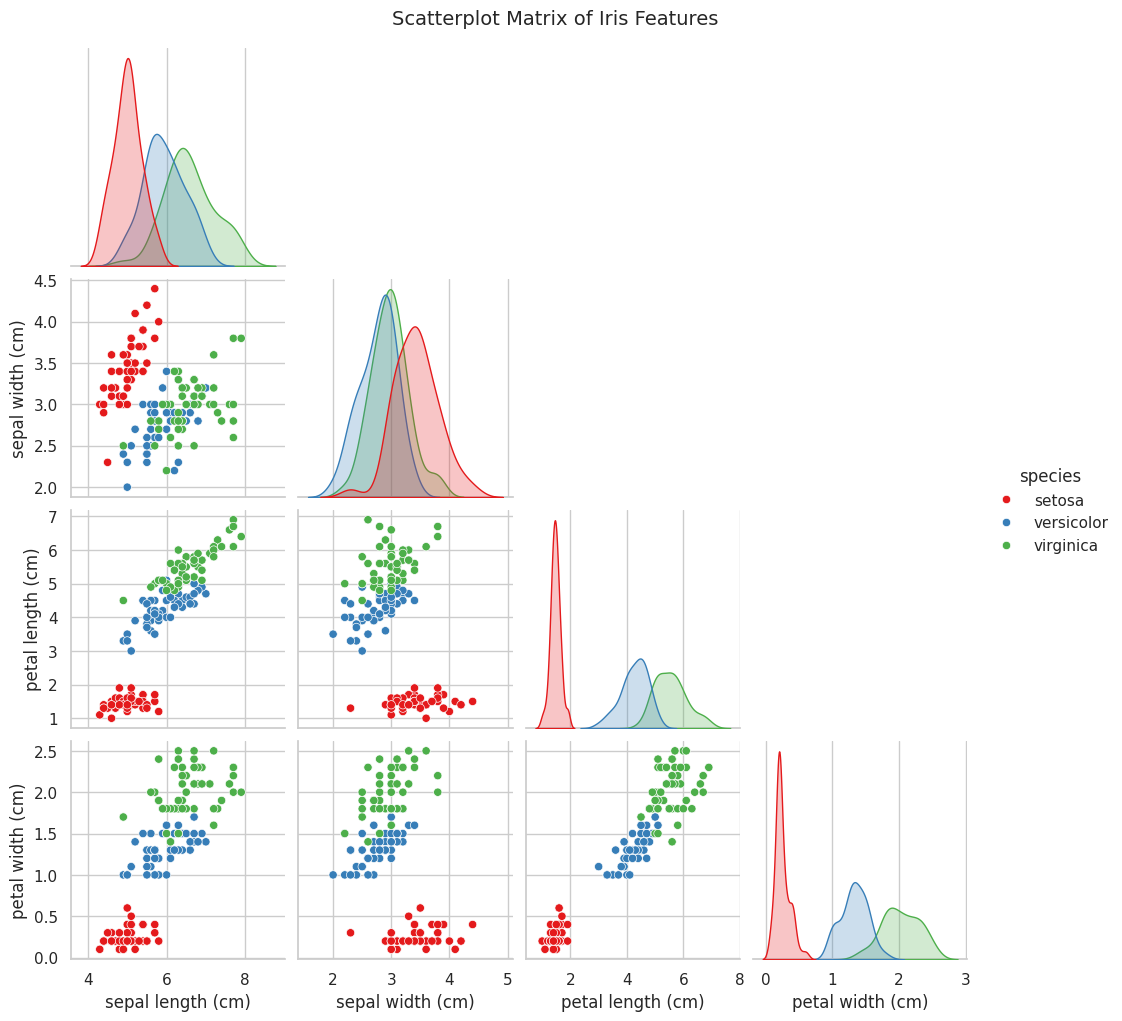

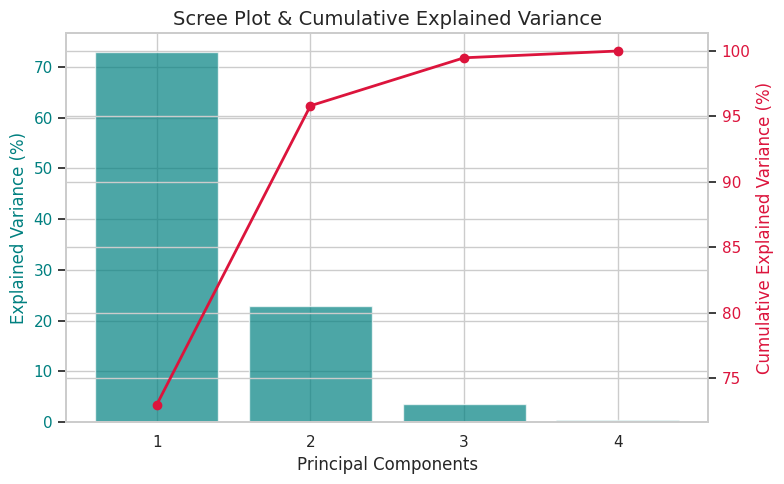

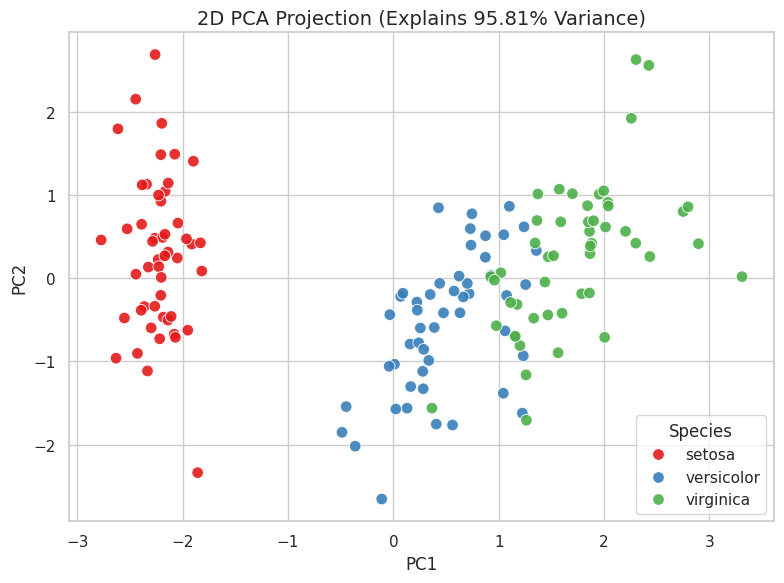

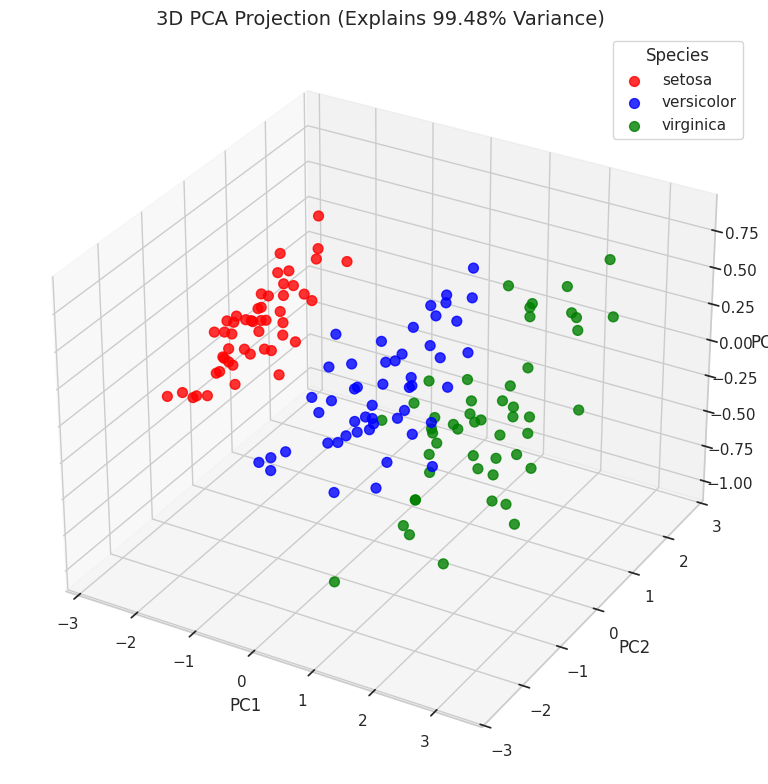

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pandas.plotting import parallel_coordinates

# 1. Load a suitable high-dimensional dataset (Iris dataset: 4 numerical features, 1 class target)
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in iris.target]
features = iris.feature_names

print("Dataset loaded successfully. Shape:", df.shape)

# Set plotting style
sns.set_theme(style="whitegrid")

# 2. Parallel Coordinates Plot
plt.figure(figsize=(10, 6))
parallel_coordinates(df, 'species', colormap='Set1', alpha=0.8)
plt.title("Parallel Coordinates Plot for Iris Features", fontsize=14)
plt.ylabel("Value (cm)")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

# 3. Scatterplot Matrix
sns.pairplot(df, hue='species', palette='Set1', corner=True)
plt.suptitle("Scatterplot Matrix of Iris Features", y=1.02, fontsize=14)
plt.show()

# 4. Standardize features before PCA
X = df[features]
y = iris.target
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform PCA up to all 4 components for variance analysis
pca_all = PCA(n_components=4)
X_pca_all = pca_all.fit_transform(X_scaled)

# 5. Scree Plot & Cumulative Explained Variance Plot
exp_var = pca_all.explained_variance_ratio_ * 100
cum_exp_var = np.cumsum(exp_var)

fig, ax1 = plt.subplots(figsize=(8, 5))

# Bar plot for individual explained variance (Scree Plot)
ax1.bar(range(1, 5), exp_var, alpha=0.7, color='teal', label='Individual Variance')
ax1.set_xlabel('Principal Components')
ax1.set_ylabel('Explained Variance (%)', color='teal')
ax1.tick_params(axis='y', labelcolor='teal')
ax1.set_xticks(range(1, 5))

# Line plot for cumulative explained variance
ax2 = ax1.twinx()
ax2.plot(range(1, 5), cum_exp_var, marker='o', color='crimson', linewidth=2, label='Cumulative Variance')
ax2.set_ylabel('Cumulative Explained Variance (%)', color='crimson')
ax2.tick_params(axis='y', labelcolor='crimson')

plt.title('Scree Plot & Cumulative Explained Variance', fontsize=14)
fig.tight_layout()
plt.show()

# 6. Perform PCA for 2D and 3D Visualizations
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

# 2D PCA Visualization
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_pca_3d[:, 0],
    y=X_pca_3d[:, 1],
    hue=df['species'],
    palette='Set1',
    s=70,
    alpha=0.9
)
plt.title(f"2D PCA Projection (Explains {cum_exp_var[1]:.2f}% Variance)", fontsize=14)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title='Species')
plt.tight_layout()
plt.show()

# 3D PCA Visualization
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

colors = {'setosa': 'red', 'versicolor': 'blue', 'virginica': 'green'}

for species_name, color in colors.items():
    mask = df['species'] == species_name
    ax.scatter(
        X_pca_3d[mask, 0],
        X_pca_3d[mask, 1],
        X_pca_3d[mask, 2],
        label=species_name,
        c=color,
        s=50,
        alpha=0.8
    )

ax.set_title(f"3D PCA Projection (Explains {cum_exp_var[2]:.2f}% Variance)", fontsize=14)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend(title='Species')
plt.tight_layout()
plt.show()